In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

In [36]:
df = pd.read_csv('dataset.csv', index_col=0)

In [37]:
df.shape    # (antall rader, antall kolonner)
df.head()   # de 5 første radene
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          114000 non-null  str    
 1   artists           113999 non-null  str    
 2   album_name        113999 non-null  str    
 3   track_name        113999 non-null  str    
 4   popularity        114000 non-null  int64  
 5   duration_ms       114000 non-null  int64  
 6   explicit          114000 non-null  bool   
 7   danceability      114000 non-null  float64
 8   energy            114000 non-null  float64
 9   key               114000 non-null  int64  
 10  loudness          114000 non-null  float64
 11  mode              114000 non-null  int64  
 12  speechiness       114000 non-null  float64
 13  acousticness      114000 non-null  float64
 14  instrumentalness  114000 non-null  float64
 15  liveness          114000 non-null  float64
 16  valence           114000 non-nu

In [38]:
df.isna().sum()      # antall manglende per kolonne
df = df.dropna()     # fjern radene som mangler noe

In [39]:
df['track_genre'].nunique()        # antall sjangre
df['track_genre'].value_counts()   # sanger per sjanger

track_genre
acoustic       1000
afrobeat       1000
alt-rock       1000
alternative    1000
ambient        1000
               ... 
trance         1000
trip-hop       1000
turkish        1000
world-music    1000
k-pop           999
Name: count, Length: 114, dtype: int64

In [40]:
df['track_id'].duplicated().sum()  # sanger som finnes flere ganger

np.int64(24259)

In [41]:
par = df[df['track_genre'].isin(['house', 'trance'])]
par = par.drop_duplicates(subset='track_id', keep=False)
par['track_genre'].value_counts()

track_genre
house     957
trance    957
Name: count, dtype: int64

In [42]:
egenskaper = ['danceability', 'energy', 'loudness', 'acousticness',
              'speechiness', 'instrumentalness', 'valence']

par.groupby('track_genre')[egenskaper].mean()

,danceability,energy,loudness,acousticness,speechiness,instrumentalness,valence
track_genre,,,,,,,
house,0.665532,0.753462,-5.274562,0.109549,0.067436,0.038312,0.493658
trance,0.576632,0.847578,-6.380929,0.033487,0.078195,0.440008,0.266969


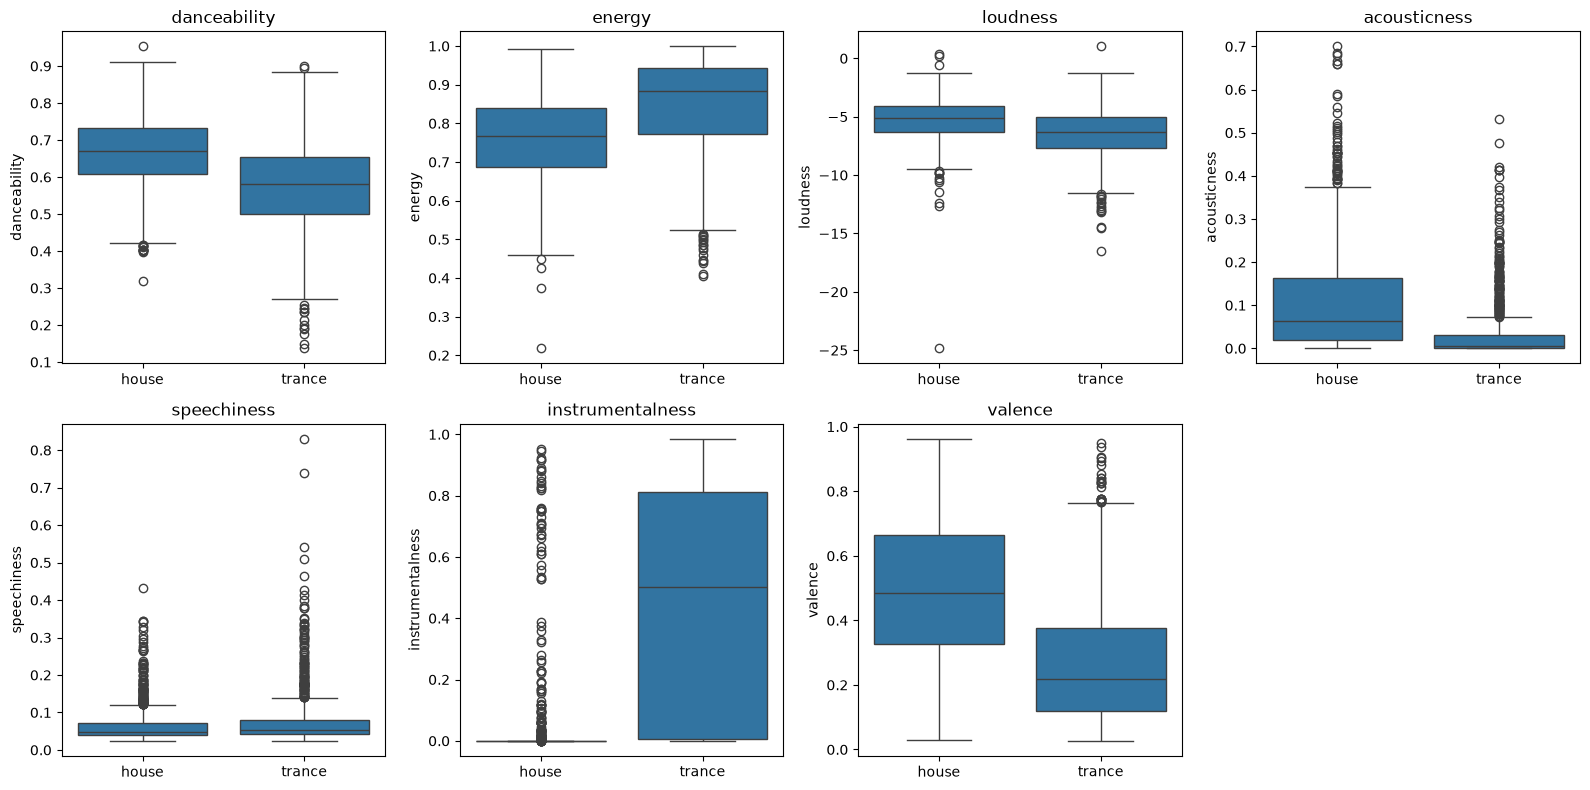

In [43]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, e in zip(axes.flat, egenskaper):
    sns.boxplot(data=par, x='track_genre', y=e, ax=ax)
    ax.set_title(e)
    ax.set_xlabel('')
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

In [44]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)

In [45]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

In [46]:
X = par[egenskaper]
y = (par['track_genre'] == 'house').astype(int)   # house = 1, trance = 0

In [47]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=10)
X_test, X_val, y_test, y_val = train_test_split(
    X_test, y_test, test_size=0.5, stratify=y_test, random_state=10)

print(len(X_train), len(X_val), len(X_test))

1339 288 287


In [48]:
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [49]:
lr = LogisticRegression()
lr.fit(X_train, y_train)

print("Feilrate trening:   ", round(1 - lr.score(X_train, y_train), 4))
print("Feilrate validering:", round(1 - lr.score(X_val, y_val), 4))

Feilrate trening:    0.1501
Feilrate validering: 0.1424


instrumentalness   -1.237499
energy             -0.781028
speechiness        -0.457982
acousticness        0.491314
valence             0.518501
danceability        0.524400
loudness            0.615315
dtype: float64


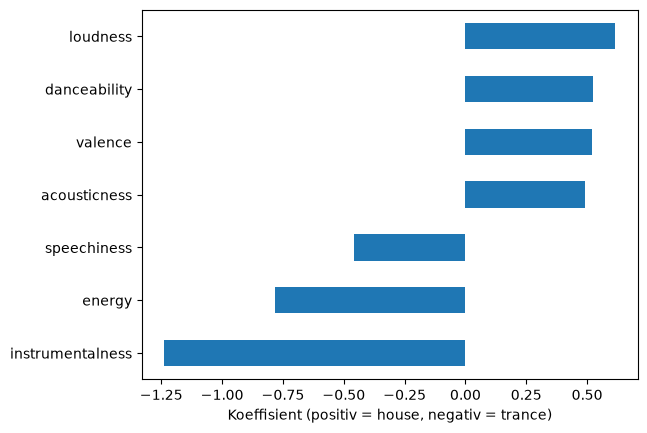

In [50]:
koef = pd.Series(lr.coef_[0], index=egenskaper).sort_values()
print(koef)

koef.plot(kind='barh')
plt.xlabel('Koeffisient (positiv = house, negativ = trance)')
plt.show()

In [51]:
val_prob = lr.predict_proba(X_val)[:, 1]

for c in np.arange(0.1, 1.0, 0.1):
    pred = np.where(val_prob > c, 1, 0)
    print("cutoff:", round(c, 1),
          "feilrate:", round(1 - accuracy_score(y_val, pred), 4))

cutoff: 0.1 feilrate: 0.2812
cutoff: 0.2 feilrate: 0.2257
cutoff: 0.3 feilrate: 0.1771
cutoff: 0.4 feilrate: 0.1424
cutoff: 0.5 feilrate: 0.1424
cutoff: 0.6 feilrate: 0.1528
cutoff: 0.7 feilrate: 0.1354
cutoff: 0.8 feilrate: 0.1875
cutoff: 0.9 feilrate: 0.3333


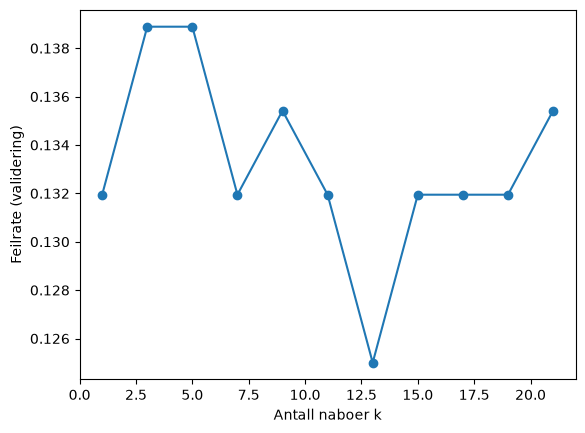

     k  feilrate
0    1  0.131944
1    3  0.138889
2    5  0.138889
3    7  0.131944
4    9  0.135417
5   11  0.131944
6   13  0.125000
7   15  0.131944
8   17  0.131944
9   19  0.131944
10  21  0.135417


In [52]:
knaboer = np.arange(1, 22, 2)
val_feilrate = []

for k in knaboer:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    val_feilrate.append(1 - knn.score(X_val, y_val))

plt.plot(knaboer, val_feilrate, marker='o')
plt.xlabel('Antall naboer k')
plt.ylabel('Feilrate (validering)')
plt.show()

print(pd.DataFrame({'k': knaboer, 'feilrate': val_feilrate}))

In [53]:
cutoff = 0.5   # replace with the best value from step 12

y_pred_lr = np.where(lr.predict_proba(X_test)[:, 1] > cutoff, 1, 0)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_lr).ravel()

print("Feilrate:    ", round(1 - accuracy_score(y_test, y_pred_lr), 4))
print("Sensitivitet:", round(tp / (tp + fn), 4))
print("Spesifisitet:", round(tn / (tn + fp), 4))

pd.DataFrame(confusion_matrix(y_test, y_pred_lr),
             index=['true:trance', 'true:house'],
             columns=['pred:trance', 'pred:house'])

Feilrate:     0.122
Sensitivitet: 0.9028
Spesifisitet: 0.8531


,pred:trance,pred:house
true:trance,122,21
true:house,14,130


In [56]:
k = 9   # replace with the best value from step 13

knn = KNeighborsClassifier(n_neighbors=k)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_knn).ravel()

print("Feilrate:    ", round(1 - accuracy_score(y_test, y_pred_knn), 4))
print("Sensitivitet:", round(tp / (tp + fn), 4))
print("Spesifisitet:", round(tn / (tn + fp), 4))

pd.DataFrame(confusion_matrix(y_test, y_pred_knn),
             index=['true:trance', 'true:house'],
             columns=['pred:trance', 'pred:house'])

Feilrate:     0.1289
Sensitivitet: 0.8958
Spesifisitet: 0.8462


,pred:trance,pred:house
true:trance,121,22
true:house,15,129
